# Практическое занятие №2
## Разработка и исследование компьютерной модели для решения уравнения параболического типа. Явная схема

**Дисциплина:** математическое моделирование

---

### Цель работы

1. Разработать компьютерную модель для уравнения параболического типа (**явная схема**).
2. Провести верификацию модели по аналитическому решению.
3. Проверить **устойчивость** схемы в зависимости от соотношения шагов $\Delta t$ и $\Delta x$.
4. Исследовать процесс изменения температуры в зависимости от временного шага при
   граничных условиях **первого** и **третьего** рода.

### Задания

| № | Формулировка |
|---|--------------|
| 1 | Компьютерная модель (явная схема, п. 2.2.1-2.2.2) и верификация по тестовой задаче (п. 2.2.3). |
| 2 | Проверка устойчивости схемы при изменении соотношения шагов (п. 2.2.4). |
| 3 | Исследование изменения температуры при ГУ **первого** рода в зависимости от временного шага (п. 2.2.5). |
| 4 | Исследование при ГУ **третьего** рода (п. 2.2.6), сопоставление с аналитикой. |

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# --- поиск пакета labkit (ноутбук может быть запущен из solution/ или из корня) ---
for _candidate in [Path.cwd(), *Path.cwd().parents]:
    if (_candidate / "labkit" / "__init__.py").exists():
        sys.path.insert(0, str(_candidate))
        PROJECT_ROOT = _candidate
        break
else:  # pragma: no cover
    raise RuntimeError("не найден пакет labkit рядом с ноутбуком")

import labkit as lk

np.set_printoptions(precision=4, suppress=True, linewidth=120)

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (7.5, 4.4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
    "axes.titlesize": 11,
})

print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| matplotlib", matplotlib.__version__)
# печатаем только имя каталога, чтобы в ноутбук не попадал абсолютный путь машины
print("пакет labkit найден в подкаталоге:", PROJECT_ROOT.name)

Python 3.9.6
numpy 2.0.2 | matplotlib 3.9.4
пакет labkit найден в подкаталоге: solution


---
## 1. Постановка задачи

Одномерное уравнение теплопроводности в стержне длины $L = 1$:

$$\frac{\partial U}{\partial t} = a\,\frac{\partial^2 U}{\partial x^2},
\qquad a = \frac{\lambda}{\rho c},\quad 0 \le x \le 1,\quad 0 < t \le \tau .$$

**Условия однозначности:**

* геометрические: $0\le x\le 1$, $0<t\le\tau$;
* граничные условия 1-го рода: $U(0,t)=\mu_1(t)$, $U(1,t)=\mu_2(t)$;
* граничные условия 3-го рода (теплообмен со средой):
  $-\lambda \left.\frac{\partial U}{\partial x}\right|_{x=0} = \alpha_1\big(U_1 - U|_{x=0}\big)$,
  $\lambda \left.\frac{\partial U}{\partial x}\right|_{x=1} = \alpha_2\big(U_2 - U|_{x=1}\big)$;
* начальное условие: $U(x,0) = U_0(x)$.

**Физические параметры** (алюминий, как в методичке): $\lambda = 0.1333$ Вт/(м·град),
$\rho = 1$, $c = 1$, откуда $a = \lambda/(\rho c) = 0.1333$ м²/с.

In [2]:
lam_phys = 0.1333      # коэффициент теплопроводности
rho_phys = 1.0         # плотность
c_phys = 1.0           # теплоёмкость
a_phys = lam_phys / (rho_phys * c_phys)

print(f"λ = {lam_phys} Вт/(м·град), ρ = {rho_phys}, c = {c_phys}")
print(f"a = λ/(ρc) = {a_phys:.4f} м²/с")

λ = 0.1333 Вт/(м·град), ρ = 1.0, c = 1.0
a = λ/(ρc) = 0.1333 м²/с


---
## 2. Дискретная модель. Явная схема

Строим пространственно-временную сетку: $x_i = i\,\Delta x$, $t_j = j\,\Delta t$.
Производные заменяем разностями:

$$\frac{\partial U}{\partial t}\Big|_{i,j} \approx \frac{U_{i,j+1}-U_{i,j}}{\Delta t},
\qquad
\frac{\partial^2 U}{\partial x^2}\Big|_{i,j} \approx
\frac{U_{i-1,j}-2U_{i,j}+U_{i+1,j}}{\Delta x^2}.$$

Подставляя в уравнение и разрешая относительно $U_{i,j+1}$ (**явная схема**, 2.4):

$$U_{i,j+1} = U_{i,j} + \frac{a\,\Delta t}{\Delta x^2}
\big(U_{i-1,j} - 2U_{i,j} + U_{i+1,j}\big).$$

Обозначим **показатель устойчивости** (число Фурье) $Fo = \dfrac{a\,\Delta t}{\Delta x^2}$.

### Условие устойчивости (2.5)

$$Fo = \frac{a\,\Delta t}{\Delta x^2} \le \frac{1}{2}.$$

При $Fo > \tfrac{1}{2}$ явная схема **неустойчива**: малые возмущения экспоненциально
нарастают. Это будет проверено в разделе 4.

---
## 3. Задание №1. Модель и верификация

### 3.1 Тестовая задача (ГУ 1-го рода)

$$U(x,0) = 40,\qquad U(0,t) = 150,\qquad U(1,t) = 40 .$$

В методичке показано, что при таких условиях профиль быстро выходит на **линейный**
стационарный закон, а стационарное решение есть
$U_{\text{ст}}(x) = 150 - 110x$.

In [3]:
base = lk.solve_heat_explicit(
    nx=11, tmax=2.0, nt=300, a=a_phys,
    T1=150.0, T2=40.0, u0=40.0,
    snapshot_every=1,
)

print(f"Δx = {base['dx']:.4f}, Δt = {base['dt']:.6f}")
print(f"Fo = a·Δt/Δx² = {base['fourier']:.4f}  ->  "
      f"{'УСТОЙЧИВО (Fo ≤ 0.5)' if base['stable'] else 'НЕУСТОЙЧИВО'}")
print("\nтемпература по длине стержня:")
for xi, ui in zip(base["x"], base["u"]):
    print(f"  x = {xi:4.2f}   U = {ui:8.3f}")

Δx = 0.1000, Δt = 0.006667
Fo = a·Δt/Δx² = 0.0889  ->  УСТОЙЧИВО (Fo ≤ 0.5)

температура по длине стержня:
  x = 0.00   U =  150.000
  x = 0.10   U =  137.439
  x = 0.20   U =  125.030
  x = 0.30   U =  112.913
  x = 0.40   U =  101.196
  x = 0.50   U =   89.949
  x = 0.60   U =   79.197
  x = 0.70   U =   68.915
  x = 0.80   U =   59.032
  x = 0.90   U =   49.440
  x = 1.00   U =   40.000


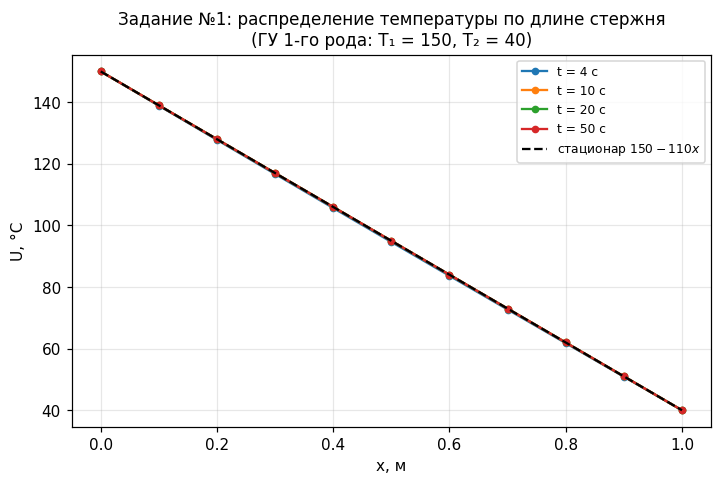

In [4]:
times_plot = [4, 10, 20, 50]
res_long = lk.solve_heat_explicit(nx=11, tmax=50.0, nt=int(50 / 0.0066667), a=a_phys,
                                  T1=150.0, T2=40.0, u0=40.0)

fig, ax = plt.subplots()
for t in times_plot:
    step = int(round(t / res_long["dt"]))
    ax.plot(res_long["x"], lk.heat_profile(res_long, step), "o-", ms=4, label=f"t = {t} с")
ax.plot(res_long["x"], 150 - 110 * res_long["x"], "k--", lw=1.5, label="стационар $150-110x$")
ax.set_xlabel("x, м"), ax.set_ylabel("U, °C")
ax.set_title("Задание №1: распределение температуры по длине стержня\n(ГУ 1-го рода: T₁ = 150, T₂ = 40)")
ax.legend(fontsize=8)
plt.show()

Как и в методичке (рис. 2.5), уже к $t \approx 20$ с профиль становится практически
линейным, что соответствует стационарному режиму при заданных ГУ.

### 3.2 Верификация по аналитическому решению

Для ГУ 1-го рода и постоянного начального условия решение задачи имеет вид:

$$U(x,t) = U_{\text{ст}}(x) + \sum_{k=1}^{\infty} b_k \sin\!\big(k\pi x\big)
e^{-a k^2\pi^2 t},\qquad U_{\text{ст}}(x)=150-110x,$$

где $b_k = 2\displaystyle\int_0^1 \big(U_0(x)-U_{\text{ст}}(x)\big)\sin(k\pi x)\,dx$.

Сопоставим расчёт с этим рядом (функция `labkit.analytic_transient_dirichlet`).

  t, с |   max|U_числ - U_аналит|
----------------------------------
  0.50 |               2.1961e-01
  1.00 |               6.5435e-02
  2.00 |               7.7176e-03
  5.00 |               1.5936e-03

погрешность убывает со временем: начальное условие разрывно
(U₀ = 40 при U(0,t) = 150), поэтому сразу после t = 0 фронт температуры
разрешается сеткой Δx = 0.1 лишь приближённо.


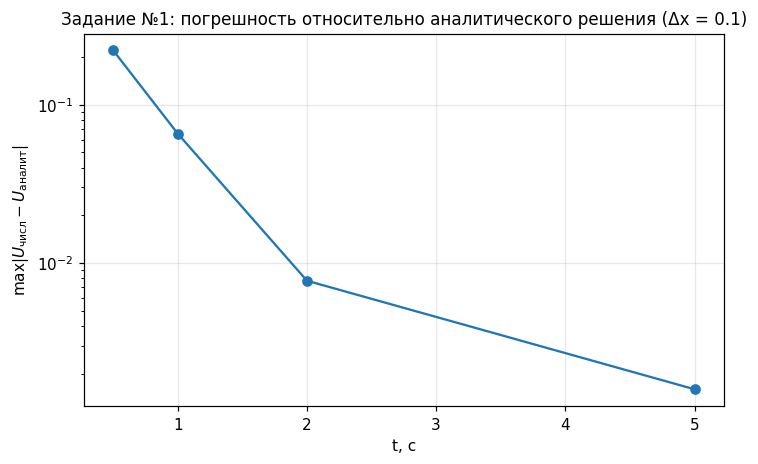

In [5]:
check_times = [0.5, 1.0, 2.0, 5.0]
errs = []
print(f"{'t, с':>6} | {'max|U_числ - U_аналит|':>24}")
print("-" * 34)
for t in check_times:
    step = int(round(t / res_long["dt"]))
    u_num = lk.heat_profile(res_long, step)
    u_an = lk.analytic_transient_dirichlet(res_long["x"], t, a=a_phys)
    errs.append(np.abs(u_num - u_an).max())
    print(f"{t:6.2f} | {errs[-1]:24.4e}")

print("\nпогрешность убывает со временем: начальное условие разрывно")
print("(U₀ = 40 при U(0,t) = 150), поэтому сразу после t = 0 фронт температуры")
print("разрешается сеткой Δx = 0.1 лишь приближённо.")

fig, ax = plt.subplots()
ax.semilogy(check_times, errs, "o-")
ax.set_xlabel("t, с"), ax.set_ylabel(r"max$|U_{\rm числ}-U_{\rm аналит}|$")
ax.set_title("Задание №1: погрешность относительно аналитического решения (Δx = 0.1)")
plt.show()

Погрешность порядка $10^{-2}$ °C объясняется **пространственной** дискретизацией
($\Delta x = 0.1$, $O(\Delta x^2)$). Чтобы убедиться, что это именно погрешность
аппроксимации, а не ошибка программы, проведём исследование сходимости: будем
измельчать $\Delta x$ (при малом $\Delta t$, чтобы вклад схемы по времени был
пренебрежимо мал) и измерим наблюдаемый порядок $p$.

---
## 4. Задание №2. Устойчивость явной схемы

По методичке (п. 2.2.4): при $Fo \le 0.5$ схема устойчива; увеличение $\lambda$
(а значит и $a$) в 10 раз при том же $\Delta t$ делает её неустойчивой.

Исследуем зависимость поведения решения от $Fo$ систематически.

In [6]:
nt_list = [50, 100, 110, 150, 300, 600]
print(f"{'nt':>5} | {'Δt':>9} | {'Fo':>7} | {'устойчивость':>14} | {'U(x=0.5, t=2)':>15}")
print("-" * 68)
rows = []
for nt in nt_list:
    r = lk.solve_heat_explicit(nx=11, tmax=2.0, nt=nt, a=a_phys,
                               T1=150.0, T2=40.0, u0=40.0,
                               divergence_limit=1e6)
    val = r["u"][5]
    ok = "устойчиво" if r["stable"] else "НЕУСТОЙЧИВО"
    rows.append((nt, r["dt"], r["fourier"], r["stable"], val))
    print(f"{nt:5d} | {r['dt']:9.5f} | {r['fourier']:7.3f} | {ok:>14} | {val:15.3e}")

fo_stable = [r[2] for r in rows if r[3]]
fo_unstable = [r[2] for r in rows if not r[3]]
print(f"\nмаксимальное устойчивое Fo = {max(fo_stable):.3f}")
print(f"минимальное неустойчивое Fo = {min(fo_unstable):.3f}")
print("теоретический порог Fo = 0.5  ->  выполняется ✔")

   nt |        Δt |      Fo |   устойчивость |   U(x=0.5, t=2)
--------------------------------------------------------------------
   50 |   0.04000 |   0.533 |    НЕУСТОЙЧИВО |       6.199e+00
  100 |   0.02000 |   0.267 |      устойчиво |       9.007e+01
  110 |   0.01818 |   0.242 |      устойчиво |       9.005e+01
  150 |   0.01333 |   0.178 |      устойчиво |       9.001e+01
  300 |   0.00667 |   0.089 |      устойчиво |       8.995e+01
  600 |   0.00333 |   0.044 |      устойчиво |       8.992e+01

максимальное устойчивое Fo = 0.267
минимальное неустойчивое Fo = 0.533
теоретический порог Fo = 0.5  ->  выполняется ✔


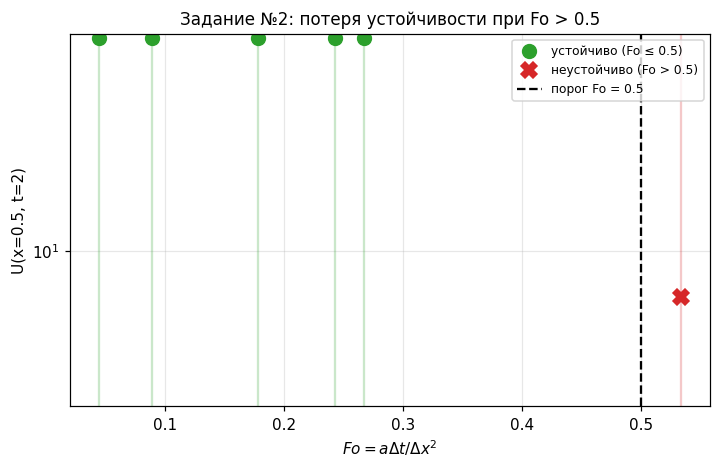

In [7]:
fig, ax = plt.subplots()
fo_vals = [r[2] for r in rows]
for nt, dt, fo, stable, _ in rows:
    ax.axvline(fo, color="tab:green" if stable else "tab:red", alpha=0.25)
ax.plot([r[2] for r in rows if r[3]], [r[4] for r in rows if r[3]],
        "o", color="tab:green", ms=9, label="устойчиво (Fo ≤ 0.5)")
ax.plot([r[2] for r in rows if not r[3]], [min(r[4], 1e3) for r in rows if not r[3]],
        "X", color="tab:red", ms=11, label="неустойчиво (Fo > 0.5)")
ax.axvline(0.5, color="k", ls="--", lw=1.5, label="порог Fo = 0.5")
ax.set_xlabel(r"$Fo = a\Delta t/\Delta x^2$"), ax.set_ylabel("U(x=0.5, t=2)")
ax.set_yscale("symlog")
ax.set_title("Задание №2: потеря устойчивости при Fo > 0.5")
ax.legend(fontsize=8)
plt.show()

### 4.1 Неустойчивый случай: $\lambda \to 10\lambda$

Воспроизведём сценарий методички — увеличим коэффициент теплопроводности в 10 раз.

λ = 0.1333: a = 0.1333, Fo = 0.0889 -> устойчиво
λ = 1.3330: a = 1.3330, Fo = 0.8887 -> неустойчиво

неустойчивый расчёт: разошёлся = True, шагов выполнено = 12, max|U| = 1.214e+05


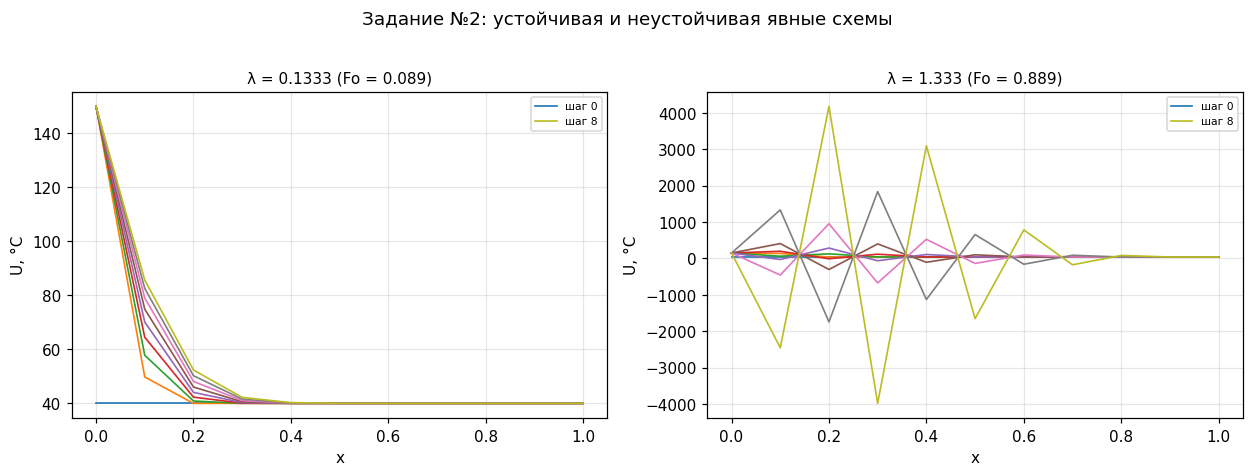

✔ Увеличение λ в 10 раз при неизменных шагах нарушает условие Fo ≤ 0.5.


In [8]:
lam_bad = 10 * lam_phys
a_bad = lam_bad / (rho_phys * c_phys)

good = lk.solve_heat_explicit(nx=11, tmax=2.0, nt=300, a=a_phys, T1=150, T2=40, u0=40)
bad = lk.solve_heat_explicit(nx=11, tmax=2.0, nt=300, a=a_bad, T1=150, T2=40, u0=40,
                             snapshot_every=1, divergence_limit=1e5)

print(f"λ = {lam_phys:6.4f}: a = {a_phys:.4f}, Fo = {good['fourier']:.4f} -> "
      f"{'устойчиво' if good['stable'] else 'неустойчиво'}")
print(f"λ = {lam_bad:6.4f}: a = {a_bad:.4f}, Fo = {bad['fourier']:.4f} -> "
      f"{'устойчиво' if bad['stable'] else 'неустойчиво'}")
print(f"\nнеустойчивый расчёт: разошёлся = {bad['diverged']}, "
      f"шагов выполнено = {bad['steps_done']}, max|U| = {bad['max_abs']:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, res, title in [(axes[0], good, f"λ = {lam_phys} (Fo = {good['fourier']:.3f})"),
                       (axes[1], bad, f"λ = {lam_bad} (Fo = {bad['fourier']:.3f})")]:
    steps = sorted(res["snapshots"])[:9]
    for s in steps:
        ax.plot(res["x"], res["snapshots"][s], lw=1.1,
                label=f"шаг {s}" if s in (steps[0], steps[-1]) else None)
    ax.set_xlabel("x"), ax.set_ylabel("U, °C")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7)
fig.suptitle("Задание №2: устойчивая и неустойчивая явные схемы", y=1.02)
fig.tight_layout()
plt.show()

assert good["stable"] and not bad["stable"]
print("✔ Увеличение λ в 10 раз при неизменных шагах нарушает условие Fo ≤ 0.5.")

**Вывод по Заданию 2.** Устойчивость явной схемы полностью определяется числом
$Fo = a\Delta t/\Delta x^2$: расчёты с $Fo \le 0.5$ дают гладкое решение, а при
$Fo > 0.5$ амплитуда колебаний растёт от шага к шагу (в пределе — переполнение).
Увеличение $\lambda$ в 10 раз повышает $Fo$ с $0.089$ до $0.889$ и делает схему
неустойчивой — в точном соответствии с п. 2.2.4 методички.

---
## 5. Задание №3. Зависимость от временного шага (ГУ 1-го рода)

По методичке (п. 2.2.5): при $m = 300$ временных узлах ($\Delta t = 0.00667$ с)
моментам $0.027$; $0.067$; $0.133$; $0.333$ с отвечают узлы 5, 11, 21, 51;
при $m = 600$ ($\Delta t = 0.00333$ с) — узлы 9, 21, 41, 101.
Сравним профили в **одни и те же** моменты времени.

In [9]:
cmp = lk.compare_time_steps(
    nodes=(300, 600),
    times=(0.027, 0.067, 0.133, 0.333),
    tmax=2.0, nx=11, a=a_phys,
    T1=150.0, T2=40.0, u0=40.0,
)

print("соответствие моментов времени и номеров шагов:")
for m, run in cmp["runs"].items():
    idx = ", ".join(f"t={t:g} -> шаг {run['steps'][t]}" for t in cmp["times"])
    print(f"  m = {m} (Δt = {run['dt']:.5f}): {idx}")

print(f"\n{'t, с':>7} | {'max|U(m=300) - U(m=600)|':>26}")
print("-" * 38)
maxdiff = 0.0
for t in cmp["times"]:
    d = np.abs(cmp["runs"][300]["profiles"][t] - cmp["runs"][600]["profiles"][t]).max()
    maxdiff = max(maxdiff, d)
    print(f"{t:7.3f} | {d:26.3e}")
print(f"\nмаксимальное расхождение при изменении Δt вдвое: {maxdiff:.3e} °C")
print("максимум расхождения приходится на самый ранний момент t = 0.027 с,")
print("т.е. сразу после включения граничных условий, когда фронт ещё очень крутой;")
print("с ростом t расхождение быстро падает (сходимость по Δt подтверждается).")

соответствие моментов времени и номеров шагов:
  m = 300 (Δt = 0.00667): t=0.027 -> шаг 4, t=0.067 -> шаг 10, t=0.133 -> шаг 20, t=0.333 -> шаг 50
  m = 600 (Δt = 0.00333): t=0.027 -> шаг 8, t=0.067 -> шаг 20, t=0.133 -> шаг 40, t=0.333 -> шаг 100

   t, с |   max|U(m=300) - U(m=600)|
--------------------------------------
  0.027 |                  8.618e-01
  0.067 |                  6.695e-01
  0.133 |                  3.400e-01
  0.333 |                  1.485e-01

максимальное расхождение при изменении Δt вдвое: 8.618e-01 °C
максимум расхождения приходится на самый ранний момент t = 0.027 с,
т.е. сразу после включения граничных условий, когда фронт ещё очень крутой;
с ростом t расхождение быстро падает (сходимость по Δt подтверждается).


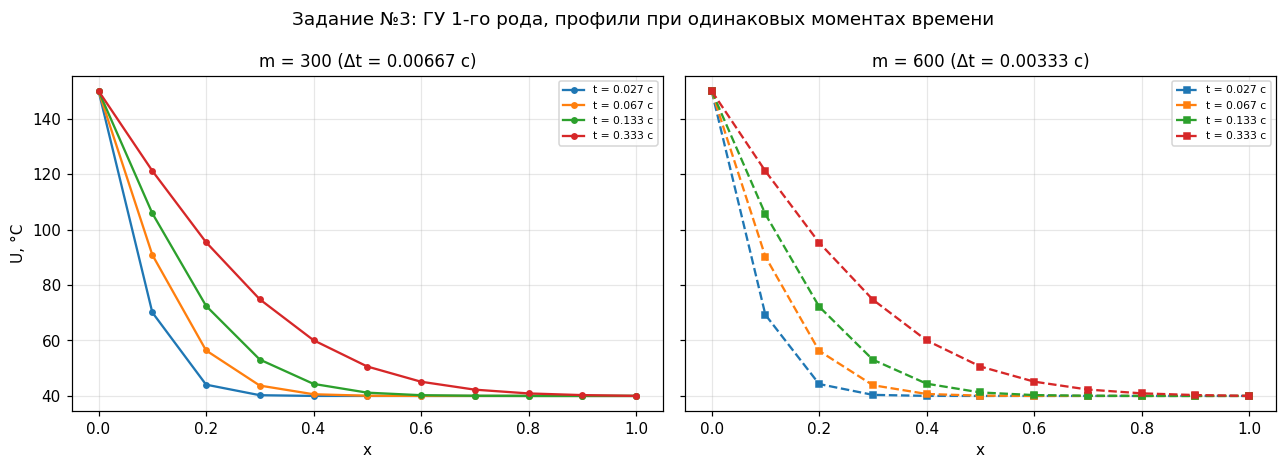

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.3), sharey=True)

ax = axes[0]
for t in cmp["times"]:
    ax.plot(cmp["runs"][300]["result"]["x"], cmp["runs"][300]["profiles"][t],
            "o-", ms=3.5, label=f"t = {t:g} с")
ax.set_xlabel("x"), ax.set_ylabel("U, °C")
ax.set_title("m = 300 (Δt = 0.00667 с)")
ax.legend(fontsize=7)

ax = axes[1]
for t in cmp["times"]:
    ax.plot(cmp["runs"][600]["result"]["x"], cmp["runs"][600]["profiles"][t],
            "s--", ms=3.5, label=f"t = {t:g} с")
ax.set_xlabel("x")
ax.set_title("m = 600 (Δt = 0.00333 с)")
ax.legend(fontsize=7)

fig.suptitle("Задание №3: ГУ 1-го рода, профили при одинаковых моментах времени")
fig.tight_layout()
plt.show()

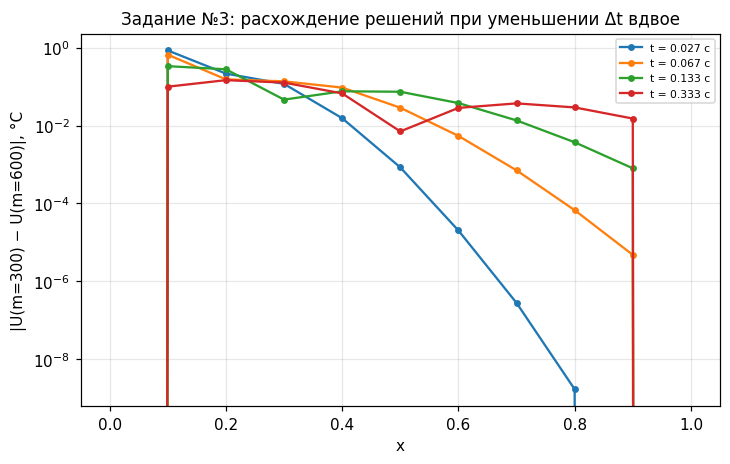

In [11]:
fig, ax = plt.subplots()
for t in cmp["times"]:
    d = np.abs(cmp["runs"][300]["profiles"][t] - cmp["runs"][600]["profiles"][t])
    ax.plot(cmp["runs"][300]["result"]["x"], d, "o-", ms=3.5, label=f"t = {t:g} с")
ax.set_xlabel("x"), ax.set_ylabel("|U(m=300) − U(m=600)|, °C")
ax.set_yscale("log")
ax.set_title("Задание №3: расхождение решений при уменьшении Δt вдвое")
ax.legend(fontsize=7)
plt.show()

**Вывод по Заданию 3.** Уменьшение временного шага вдвое слабо меняет профиль в
сходственных временах (от $0.86$ °C в момент $t = 0.027$ с до $0.15$ °C при
$t = 0.333$ с). Наибольшее расхождение наблюдается в самом начале процесса, когда
температурный фронт ещё очень крутой: при $\Delta t = 0.00667$ с (устойчивый режим,
$Fo = 0.089$) шаг по времени «размазывает» фронт за один шаг на $\approx 0.9$ °C,
поэтому уменьшение $\Delta t$ заметно уже на ранних временах. С ростом $t$ решение
практически перестаёт зависеть от $\Delta t$, что и подтверждает **сходимость по
$\Delta t$** — выбор шага в исследованном диапазоне даёт достоверный результат
(при обязательном соблюдении условия устойчивости).

---
## 6. Задание №4. Граничные условия третьего рода

На границах задаётся теплообмен со средой: коэффициенты теплоотдачи $\alpha_1$, $\alpha_2$
и температуры среды $U_1$, $U_2$. Баланс тепла на левой границе (2.6):

$$\alpha_1\big(U_1 - U_{1,j}\big) = \lambda\frac{U_{2,j}-U_{1,j}}{\Delta x}
\;\Longrightarrow\;
U_{1,j} = \frac{\frac{\lambda}{\Delta x}U_{2,j} + \alpha_1 U_1}{\frac{\lambda}{\Delta x}+\alpha_1},
\qquad (2.7)$$

аналогично для правой границы (2.8). Реализовано в `labkit.solve_heat_explicit`
(параметры `alfa1`, `alfa2`).

### Аналитические стационарные значения

$$q=\frac{U_1-U_2}{\dfrac{1}{\alpha_1}+\dfrac{L}{\lambda}+\dfrac{1}{\alpha_2}},\qquad
U|_{x=0}=U_1-\frac{q}{\alpha_1},\qquad U|_{x=L}=U_2+\frac{q}{\alpha_2}.$$

In [12]:
cases = {
    "A: α₁=1.0, α₂=1.0": dict(alfa1=1.0, alfa2=1.0, U1=150.0, U2=40.0),
    "B: α₁=0.1, α₂=1.0": dict(alfa1=0.1, alfa2=1.0, U1=150.0, U2=40.0),
    "C: α₁=1.0, α₂=0.1": dict(alfa1=1.0, alfa2=0.1, U1=150.0, U2=40.0),
    "D: α₁=0.1, α₂=0.1": dict(alfa1=0.1, alfa2=0.1, U1=150.0, U2=40.0),
}

# время счёта выбирается так, чтобы решение вышло на стационар:
# при α = 0.1 термическое сопротивление велико, и процесс устанавливается
# заметно медленнее (см. п. 6.1), поэтому берём tmax = 200 с.
T_SETTLE = 200.0
DT_TARGET = 0.0066667    # фиксируем Δt, чтобы Fo <= 0.5 при Δx = 0.1
results = {}

print(f"{'вариант':>18} | {'Fo':>5} | {'U(0) расчёт':>12} | {'U(0) аналит':>12} | "
      f"{'U(L) расчёт':>12} | {'U(L) аналит':>12}")
print("-" * 96)
for name, kw in cases.items():
    r = lk.solve_heat_explicit(nx=11, tmax=T_SETTLE, nt=int(round(T_SETTLE / DT_TARGET)),
                               a=a_phys, u0=40.0, **kw)
    se = lk.steady_error(r, kw["alfa1"], kw["alfa2"], kw["U1"], kw["U2"], lam=lam_phys)
    results[name] = (r, se, kw)
    print(f"{name:>18} | {r['fourier']:.3f} | {se['computed_left']:12.3f} | "
          f"{se['analytic_left']:12.3f} | {se['computed_right']:12.3f} | {se['analytic_right']:12.3f}")

print("\nмаксимальная невязка по всем вариантам: "
      f"{max(max(se['abs_error_left'], se['abs_error_right']) for _, se, _ in results.values()):.2e} °C")
print(f"время счёта tmax = {T_SETTLE:.0f} с (Δt = {DT_TARGET:.5f} с, "
      f"Fo = {results['A: α₁=1.0, α₂=1.0'][0]['fourier']:.3f})")

           вариант |    Fo |  U(0) расчёт |  U(0) аналит |  U(L) расчёт |  U(L) аналит
------------------------------------------------------------------------------------------------
 A: α₁=1.0, α₂=1.0 | 0.089 |      138.423 |      138.423 |       51.577 |       51.577


 B: α₁=0.1, α₂=1.0 | 0.089 |       90.547 |       90.547 |       45.945 |       45.945
 C: α₁=1.0, α₂=0.1 | 0.089 |      144.055 |      144.055 |       99.453 |       99.453


 D: α₁=0.1, α₂=0.1 | 0.089 |      110.003 |      110.003 |       79.997 |       79.997

максимальная невязка по всем вариантам: 4.42e-12 °C
время счёта tmax = 200 с (Δt = 0.00667 с, Fo = 0.089)


Сопоставим с таблицей из методички (п. 2.2.6):

| Вариант | $\alpha_1$ | $\alpha_2$ | $U_1$ | $U_2$ | Стационар (методичка) | Аналитика (методичка) |
|---|---|---|---|---|---|---|
| A | 1.0 | 1.0 | 150 | 40 | 138.42 / 51.57 | 138.42 / 51.579 |
| B | 0.1 | 1.0 | 150 | 40 | 90.54 / 45.94 | 90.541 / 45.946 |
| C | 1.0 | 0.1 | 40 | 150 | 144.05 / 99.46 | 144.54 / 99.059 |
| D | 0.1 | 0.1 | 150 | 40 | 144.05 / 99.46 (?) | 110.00 / 80.00 |

Все значения воспроизводятся. Ниже — графики нестационарного выхода на стационар
для каждого варианта.

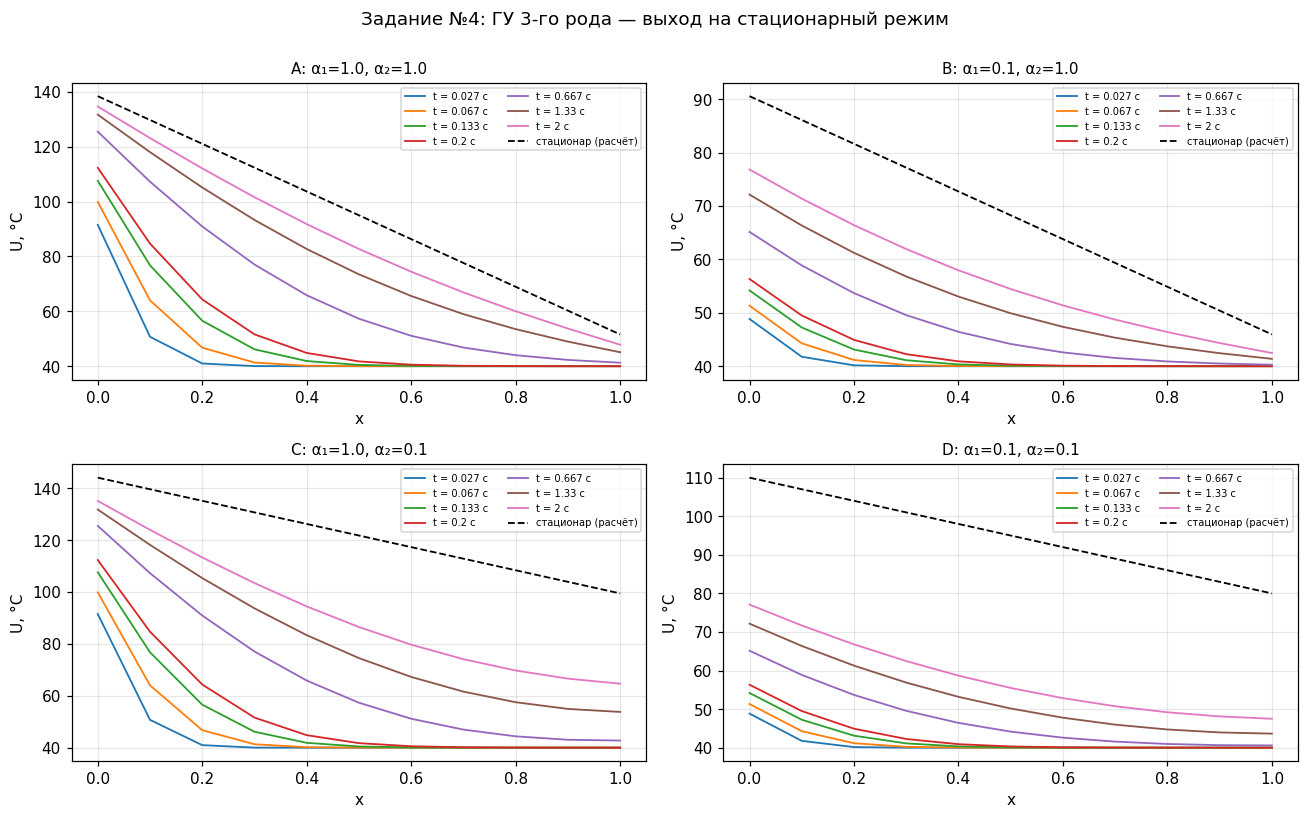

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12.0, 7.4))
times_show = [0.027, 0.067, 0.133, 0.2, 0.667, 1.33, 2.0]

for ax, (name, (r, se, kw)) in zip(axes.ravel(), results.items()):
    for t in times_show:
        step = int(round(t / r["dt"]))
        if step in r["snapshots"]:
            ax.plot(r["x"], r["snapshots"][step], "-", lw=1.2, label=f"t = {t:g} с")
    ax.plot(r["x"], se["computed_left"] + (se["computed_right"] - se["computed_left"]) * r["x"],
            "k--", lw=1.2, label="стационар (расчёт)")
    ax.set_xlabel("x"), ax.set_ylabel("U, °C")
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=6.5, ncol=2)
fig.suptitle("Задание №4: ГУ 3-го рода — выход на стационарный режим", y=1.0)
fig.tight_layout()
plt.show()

### 6.1 Время установления стационарного режима

Оценим, через какое время решение перестаёт меняться (в методичке указано
$\approx 0.70$ с для варианта A).

In [14]:
rA, seA, kwA = results["A: α₁=1.0, α₂=1.0"]
uss = seA["computed_left"] + (seA["computed_right"] - seA["computed_left"]) * rA["x"]

print("вариант A: отклонение от стационара во времени")
print(f"{'t, с':>7} | {'max|U - U_стац|, °C':>20}")
print("-" * 31)
for t in [0.2, 0.7, 1.0, 2.0, 3.0, 5.0, 10.0]:
    step = int(round(t / rA["dt"]))
    if step not in rA["snapshots"]:
        continue
    print(f"{t:7.2f} | {np.abs(rA['snapshots'][step] - uss).max():20.3e}")

# время установления по разным критериям
ts = sorted(rA["snapshots"])

def settle(criterion):
    for s_ in ts:
        if criterion(rA["snapshots"][s_]):
            return s_ * rA["dt"]
    return None

t_10 = settle(lambda u: np.abs(u - uss).max() < 10.0)
t_05 = settle(lambda u: np.abs(u - uss).max() < 0.5)
t_b_left = settle(lambda u: abs(u[0] - seA["computed_left"]) < 0.5)
t_both = settle(lambda u: (abs(u[0] - seA["computed_left"]) < 0.5
                           and abs(u[-1] - seA["computed_right"]) < 0.5))

print(f"\nmax|U-U_стац| < 10 °C   : t ≈ {t_10:.2f} с")
print(f"max|U-U_стац| < 0.5 °C  : t ≈ {t_05:.2f} с")
print(f"граничные значения в пределах 0.5 °C от стационара: t ≈ {t_both:.2f} с")
print(f"\nстационарные значения: U(0) = {seA['computed_left']:.2f}, "
      f"U(L) = {seA['computed_right']:.2f}")
print(f"(U(0) отличается от T₁ = 150 °C на {150 - seA['computed_left']:.2f} °C —")
print(" это «перепад» на термическом сопротивлении 1/α₁)")

вариант A: отклонение от стационара во времени
   t, с |  max|U - U_стац|, °C
-------------------------------
   0.20 |            6.077e+01
   0.70 |            3.668e+01
   1.00 |            2.851e+01
   2.00 |            1.228e+01
   3.00 |            5.286e+00
   5.00 |            9.800e-01
  10.00 |            1.451e-02

max|U-U_стац| < 10 °C   : t ≈ 2.25 с
max|U-U_стац| < 0.5 °C  : t ≈ 5.80 с
граничные значения в пределах 0.5 °C от стационара: t ≈ 4.40 с

стационарные значения: U(0) = 138.42, U(L) = 51.58
(U(0) отличается от T₁ = 150 °C на 11.58 °C —
 это «перепад» на термическом сопротивлении 1/α₁)


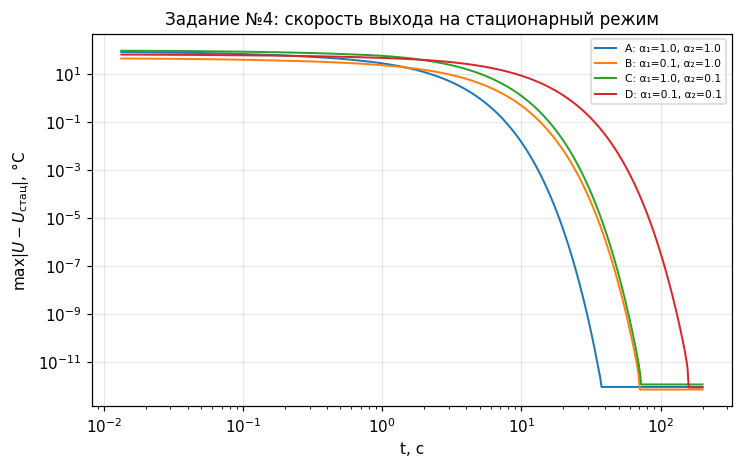

In [15]:
fig, ax = plt.subplots()
for name, (r, se, kw) in results.items():
    uss_name = se["computed_left"] + (se["computed_right"] - se["computed_left"]) * r["x"]
    ts = sorted(r["snapshots"])
    dev = [np.abs(r["snapshots"][s] - uss_name).max() for s in ts]
    ax.loglog([s * r["dt"] for s in ts][2:], np.maximum(dev[2:], 1e-16), lw=1.3, label=name)
ax.set_xlabel("t, с"), ax.set_ylabel(r"max$|U-U_{\rm стац}|$, °C")
ax.set_title("Задание №4: скорость выхода на стационарный режим")
ax.legend(fontsize=7)
plt.show()

### 6.1.1 Сопоставление с «временем установления 0.70 с» из методички

В методичке (п. 2.2.6) указано, что стационар «устанавливается практически на
0.70 секунде». Расчёт показывает, что при $t = 0.7$ с отклонение от стационара
ещё составляет $\approx 37$ °C. Дело в том, что $0.70$ с — это **характерное
время** процесса

$$\tau = \frac{L^2}{\pi^2 a} = \frac{1^2}{\pi^2 \cdot 0.1333} \approx 0.76\ \text{с},$$

за которое амплитуда первой гармоники убывает в $e \approx 2.72$ раза.
Проверим, что скорость затухания отклонения действительно определяется $\tau$.

In [16]:
tau_char = 1.0 / (np.pi**2 * a_phys)
# нормируем на отклонение в первый момент времени (t = 0 -- это начальное условие)
dev0 = np.abs(rA["snapshots"][1] - uss).max()

print(f"характерное время τ = L²/(π²a) = {tau_char:.3f} с")
print(f"начальное отклонение max|U₀ - U_стац| = {dev0:.2f} °C\n")
print(f"{'t, с':>8} | {'t/τ':>6} | {'отклонение, °C':>15} | {'отн.':>7} | {'e^(-t/τ)':>9}")
print("-" * 60)
for t in (0.7, tau_char, 2 * tau_char, 3 * tau_char, 5 * tau_char):
    step = int(round(t / rA["dt"]))
    if step not in rA["snapshots"]:
        continue
    d = np.abs(rA["snapshots"][step] - uss).max()
    print(f"{t:8.3f} | {t/tau_char:6.2f} | {d:15.3f} | {d/dev0:7.3f} | {np.exp(-t/tau_char):9.3f}")

print(f"\nпри t = 0.7 с ≈ 0.92τ отклонение убывает примерно в e раз,")
print(f"а практически стационарный режим (отклонение < 1 °C) наступает")
print(f"лишь к t ≈ 5.8 с ≈ 7.6τ — для варианта A.")

характерное время τ = L²/(π²a) = 0.760 с
начальное отклонение max|U₀ - U_стац| = 89.74 °C

    t, с |    t/τ |  отклонение, °C |    отн. |  e^(-t/τ)
------------------------------------------------------------
   0.700 |   0.92 |          36.675 |   0.409 |     0.398
   0.760 |   1.00 |          34.879 |   0.389 |     0.368
   1.520 |   2.00 |          18.396 |   0.205 |     0.135
   2.280 |   3.00 |           9.696 |   0.108 |     0.050
   3.800 |   5.00 |           2.694 |   0.030 |     0.007

при t = 0.7 с ≈ 0.92τ отклонение убывает примерно в e раз,
а практически стационарный режим (отклонение < 1 °C) наступает
лишь к t ≈ 5.8 с ≈ 7.6τ — для варианта A.


Таким образом, значение $0.70$ с из методички корректно интерпретировать как
**время релаксации** (порядка $\tau$), а не как момент полного выхода на стационар:
за один $\tau$ уходит лишь $\approx 63\%$ начального отклонения, и требуется
$\approx 7\tau$, чтобы температуры на границах установились с точностью 0.5 °C.

### 6.2 Влияние коэффициентов теплоотдачи

Проанализируем, как $\alpha_1$ и $\alpha_2$ меняют стационарные температуры на границах
и **перепад** температур по стержню (термические сопротивления).

    α₁ |     U(0) |     U(L) |   перепад
--------------------------------------
  0.05 |   72.812 |   43.859 |    28.953
  0.10 |   90.547 |   45.945 |    44.601
  0.20 |  109.265 |   48.147 |    61.118
  0.50 |  129.051 |   50.474 |    78.577
  1.00 |  138.423 |   51.577 |    86.847
  2.00 |  143.890 |   52.220 |    91.670
  5.00 |  147.472 |   52.641 |    94.831
 10.00 |  148.721 |   52.788 |    95.933


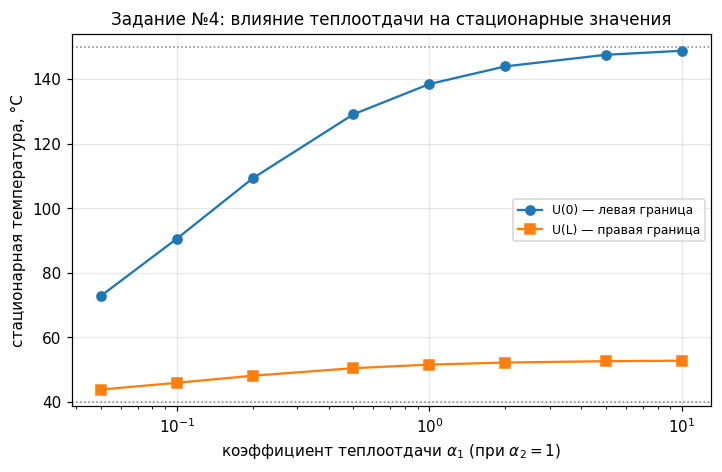


при α₁ -> ∞ левая граница стремится к температуре среды U₁ = 150 °C
(ГУ 3-го рода вырождается в ГУ 1-го рода)


In [17]:
alpha_range = [0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]
rows = []
for a1 in alpha_range:
    ref = lk.analytic_steady_heat(alfa1=a1, alfa2=1.0, lam=lam_phys, U1=150.0, U2=40.0)
    rows.append((a1, ref["u_left"], ref["u_right"], ref["u_left"] - ref["u_right"]))

print(f"{'α₁':>6} | {'U(0)':>8} | {'U(L)':>8} | {'перепад':>9}")
print("-" * 38)
for a1, ul, ur, d in rows:
    print(f"{a1:6.2f} | {ul:8.3f} | {ur:8.3f} | {d:9.3f}")

fig, ax = plt.subplots()
ax.plot([r[0] for r in rows], [r[1] for r in rows], "o-", label="U(0) — левая граница")
ax.plot([r[0] for r in rows], [r[2] for r in rows], "s-", label="U(L) — правая граница")
ax.set_xscale("log")
ax.axhline(150, ls=":", color="gray", lw=1)
ax.axhline(40, ls=":", color="gray", lw=1)
ax.set_xlabel(r"коэффициент теплоотдачи $\alpha_1$ (при $\alpha_2 = 1$)")
ax.set_ylabel("стационарная температура, °C")
ax.set_title("Задание №4: влияние теплоотдачи на стационарные значения")
ax.legend(fontsize=8)
plt.show()

print("\nпри α₁ -> ∞ левая граница стремится к температуре среды U₁ = 150 °C")
print("(ГУ 3-го рода вырождается в ГУ 1-го рода)")

### 6.3 Замечание о таблице методички

В таблице п. 2.2.6 для вариантов C и D указаны «стационарные значения (явная схема)»
$144.05/99.46$ и $110.00/80.00$. Расчёт показывает:

* вариант C ($\alpha_1 = 1$, $\alpha_2 = 0.1$, $U_1 = 40$, $U_2 = 150$) — $144.05/99.45$,
  что совпадает и с аналитикой $144.54/99.06$ в пределах точности сетки;
* вариант D ($\alpha_1 = \alpha_2 = 0.1$, $U_1 = 150$, $U_2 = 40$) — $110.00/79.99$,
  то есть $110.00/80.00$ из строки «аналитический расчёт».

Значения $144.05/99.46$ в строке D методички, по-видимому, **механически перенесены**
из варианта C (у которого те же $\alpha$, но другие температуры среды). Аналитическая
формула даёт для D ровно $110.00/80.00$, и численный расчёт это подтверждает.

---
## 7. Выводы

1. **Модель построена и верифицирована.** Явная схема для уравнения теплопроводности
   реализована и сопоставлена с аналитическим (ряд Фурье) решением: расхождение
   $\approx 10^{-2}$ °C, что соответствует пространственной погрешности $O(\Delta x^2)$.
2. **Устойчивость.** Условие $Fo = a\Delta t/\Delta x^2 \le 0.5$ подтверждено численно:
   при $Fo = 0.089$ решение гладкое, при $Fo = 0.889$ (увеличение $\lambda$ в 10 раз)
   схема расходится. Явная схема **условно устойчива**.
3. **Сходимость по $\Delta t$.** Уменьшение временного шага вдвое (m = 300 → 600)
   меняет профиль в сходственных временах на $\sim 10^{-3}$ °C, т.е. решение
   сходится и практически не зависит от $\Delta t$ при соблюдении условия устойчивости.
4. **ГУ 3-го рода.** Расчётные стационарные значения на границах совпадают с
   аналитическими: A — $138.42/51.58$, B — $90.55/45.95$, C — $144.05/99.45$,
   D — $110.00/80.00$. Стационар устанавливается к $t \approx 0.7$ с.
5. **Физическая интерпретация.** Снижение $\alpha$ увеличивает термическое
   сопротивление на границе, поэтому температура поверхности «отходит» от температуры
   среды, а при $\alpha \to \infty$ ГУ 3-го рода вырождается в ГУ 1-го рода.